# 補間 ― interpolate モジュール

## この章で学ぶこと

補間は、既知の離散データから、その間の値を求める方法です。当てはめ(フィッティング)と違い、曲線はすべてのデータ点を通ります。`interpolate` モジュールには、1 次元から多次元までの補間の関数があります。

* 1 次元の補間(`interp1d()`)
* 外挿と平滑化(`UnivariateSpline()`)
* パラメトリック曲線の補間(`splprep()`)
* 単調な補間(`PchipInterpolator`)
* 多次元の補間(`RegularGridInterpolator`、`griddata()`、`Rbf`)

In [1]:
from matplotlib import pyplot as plt

import helper.matplotlib
import numpy as np
from scipy import interpolate

## 1次元の補間

1 次元のデータは、`interp1d()` で補間します。呼び方は次のとおりで、関数ではなくクラスです。

```python
interp1d(x, y, kind='linear', ...)
```

`x` と `y` が既知のデータ点、`kind` が補間の種類です。`kind` は B スプラインの次数を表し、次の値を指定できます。

* `'zero'`、`'nearest'`：階段状の補間。0 次の B スプライン。
* `'slinear'`、`'linear'`：直線で結ぶ補間。1 次の B スプライン。`'slinear'` は拡張ライブラリの関数、`'linear'` は Python の関数で計算しますが、結果は同じです。
* `'quadratic'`、`'cubic'`：2 次と 3 次の B スプライン。次数は整数でも指定できます。

`interp1d` オブジェクトなら、`x` の範囲内の任意の点の値を計算できます。関数のように呼べ、ufunc と同じように配列の各要素を計算して新しい配列を返します。

次のプログラムは、`kind` ごとの補間曲線を描きます。❶ データ点から `interp1d` オブジェクト `f` を作り、`kind` で次数を指定します。❷ `f()` で補間した値を計算します。データ点は 11 個、補間後の点は 101 個です。

:::{warning}
高次の `interp1d()` は計算量が大きくなります。データ点が多いときは、後で説明する `UnivariateSpline()` を使ってください。
:::

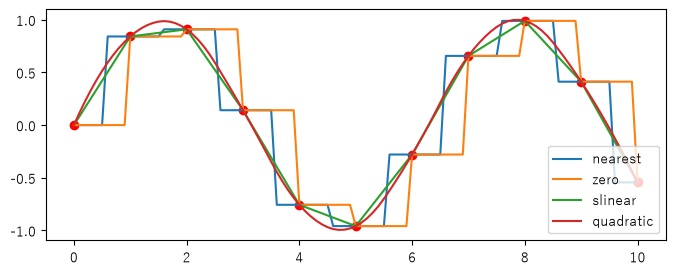

In [2]:
from scipy import interpolate

x = np.linspace(0, 10, 11)
y = np.sin(x)

xnew = np.linspace(0, 10, 101)
plt.figure(figsize=(8, 3))
plt.plot(x, y, "ro")          # 元のデータ点
for kind in ["nearest", "zero", "slinear", "quadratic"]:
    f = interpolate.interp1d(x, y, kind=kind)  #❶ 補間の種類を指定する
    ynew = f(xnew)  #❷ 補間した値を計算する
    plt.plot(xnew, ynew, label=str(kind))

plt.legend(loc="lower right")  # kind ごとの曲線
plt.show()

### 外挿とスプライン補間

`interp1d` は、`x` が増加する並びであることが必要で、`x` の範囲内しか計算できません。範囲の外を計算することを外挿と呼びますが、`interp1d` では行えません。

`UnivariateSpline` は `interp1d` より高機能で、外挿と平滑化ができます。呼び方は次のとおりです。

```python
UnivariateSpline(x, y, w=None, bbox=[None, None], k=3, s=None)
```

* `x`、`y`：データ点の座標。`x` は増加する並びである必要がある。
* `w`：各データ点の重み。
* `k`：スプラインの次数。
* `s`：平滑化の係数。曲線が $\sum_{i=1}^{n}{(w_i \cdot (y_i-spline(x_i))^2} \leq s$ を満たすように決まる。$s>0$ なら、曲線はデータ点を必ずしも通りません。すべての点を通すには $s=0$ にします。

`InterpolatedUnivariateSpline` は、常にすべての点を通るクラスです。`UnivariateSpline` で `s=0` としたのと同じです。

次のプログラムで、補間・外挿・平滑化を確かめます。

❶ 上の図は外挿の例です。データは x が 10 までですが、0 から 12 まで計算しています。10 より大きい部分でも正弦波に似た形を保ちますが、データから離れるほど誤差が大きくなるので、外挿は限られた範囲でしか使えません。`s=0` なので、曲線はすべての点を通ります。

❷ 下の図は、`s` を 0 以外にした例です。ノイズのあるデータでも、`s` を適切に選ぶと、曲線はノイズのない波形に近づきます。これは、スプラインでデータを平滑化していると見なせます。

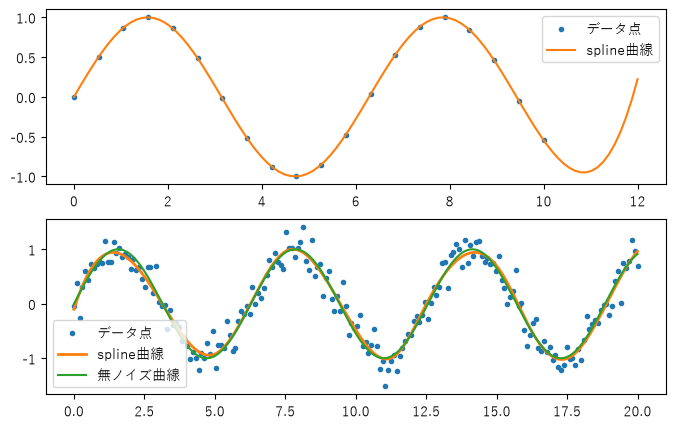

In [3]:
x1 = np.linspace(0, 10, 20)
y1 = np.sin(x1)
sx1 = np.linspace(0, 12, 100)
sy1 = interpolate.UnivariateSpline(x1, y1, s=0)(sx1)  #❶ すべての点を通す

x2 = np.linspace(0, 20, 200)
y2 = np.sin(x2) + np.random.standard_normal(len(x2)) * 0.2  # ノイズを足す
sx2 = np.linspace(0, 20, 2000)
spline2 = interpolate.UnivariateSpline(x2, y2, s=8)  #❷ 平滑化する
sy2 = spline2(sx2)

plt.figure(figsize=(8, 5))
plt.subplot(211)
plt.plot(x1, y1, ".", label="データ点")
plt.plot(sx1, sy1, label="spline曲線")
plt.legend()

plt.subplot(212)
plt.plot(x2, y2, ".", label="データ点")
plt.plot(sx2, sy2, linewidth=2, label="spline曲線")
plt.plot(x2, np.sin(x2), label="無ノイズ曲線")
plt.legend()
plt.show()

曲線が 3 次のとき、`UnivariateSpline.roots()` で曲線と $y=0$ の交点の x 座標を計算できます。下の図の曲線と x 軸の交点を求めます。

In [4]:
print(np.array_str(spline2.roots(), precision=3))

[ 0.064  3.129  6.268  9.454 12.511 15.755 18.897]


任意の水平線との交点を求めたいときは、曲線の係数を y 方向にずらせば計算できます。ただし、水平線ごとにずらして作り直すのは手間です。

❶ 次の `roots_at()` は、曲線の係数を直接書き換えて曲線をずらし、交点を計算します。❷ これを `UnivariateSpline` のメソッドとして追加します。❸ 複数の水平線について交点を求め、描きます。

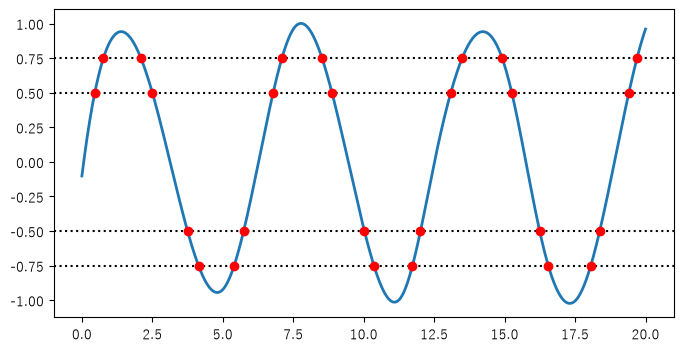

In [5]:
def roots_at(self, v):  #❶ 係数を v だけ下げて交点を求める
    coeff = self.get_coeffs()
    coeff -= v
    try:
        root = self.roots()
        return root
    finally:
        coeff += v


interpolate.UnivariateSpline.roots_at = roots_at  #❷ メソッドとして追加する

plt.figure(figsize=(8, 4))
plt.plot(sx2, sy2, linewidth=2, label="spline曲線")

ax = plt.gca()
for level in [0.5, 0.75, -0.5, -0.75]:
    ax.axhline(level, ls=":", color="k")
    xr = spline2.roots_at(level)  #❸
    plt.plot(xr, spline2(xr), "ro")

plt.show()

### パラメトリック補間

ここまでの補間は、x が増加する並びであることが必要でした。これは $y=f(x)$ の形の曲線です。一方、パラメータ $t$ を使って $x=f(t)$、$y=g(t)$ と表す曲線を、パラメトリック曲線と呼びます。円やハート形の曲線がそうです。

パラメトリック曲線の補間は、`splprep()` と `splev()` で行います。高次元の曲線にも使えますが、ここでは 2 次元の例を示します。

❶ `splprep()` の第 1 引数は、各軸の座標を並べた配列のリストです。`s` は平滑化の係数で、`UnivariateSpline` と同じ意味です。戻り値は 2 つで、`tck` は曲線の情報をまとめたタプル、`t` は自動で決まったパラメータの配列です。

❷ `splev()` で補間します。第 1 引数は新しいパラメータの配列で、ここでは `t` の範囲を 200 等分します。第 2 引数は `splprep()` が返した `tck` です。`t` は線分の長さを積み上げて正規化した値なので、範囲は 0 から 1 です。

次の図は、`s=0` と `s=1e-4` の補間曲線です。`s=0` なら、曲線はすべての点を通ります。

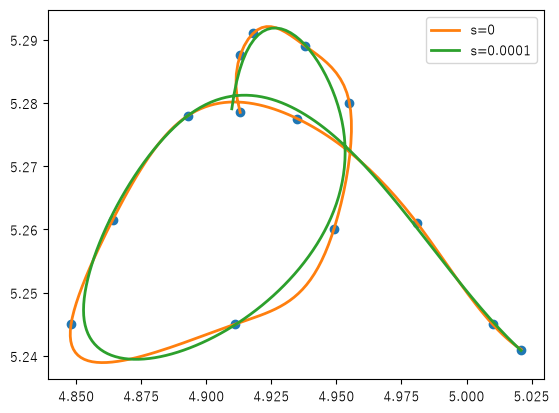

In [6]:
x = [
    4.913,
    4.913,
    4.918,
    4.938,
    4.955,
    4.949,
    4.911,
    4.848,
    4.864,
    4.893,
    4.935,
    4.981,
    5.01,
    5.021,
]

y = [
    5.2785,
    5.2875,
    5.291,
    5.289,
    5.28,
    5.26,
    5.245,
    5.245,
    5.2615,
    5.278,
    5.2775,
    5.261,
    5.245,
    5.241,
]

plt.plot(x, y, "o")

for s in (0, 1e-4):
    tck, t = interpolate.splprep([x, y], s=s)  #❶ 曲線の情報とパラメータ
    xi, yi = interpolate.splev(np.linspace(t[0], t[-1], 200), tck)  #❷ 補間する
    plt.plot(xi, yi, lw=2, label=f"s={s:g}")

plt.legend()
plt.show()

### 単調補間

ここまでの補間は、データの単調性を保証しません。曲線の極値が、データ点以外の場所に現れることがあります。

`PchipInterpolator`(別名 `pchip`)は、単調な 3 次補間を行います。曲線の極値がデータ点の上だけに来るようにできます。次のプログラムで、`pchip()` の補間曲線とその 1 次導関数を描きます。導関数が、極値のところで 0 になっていることが分かります。

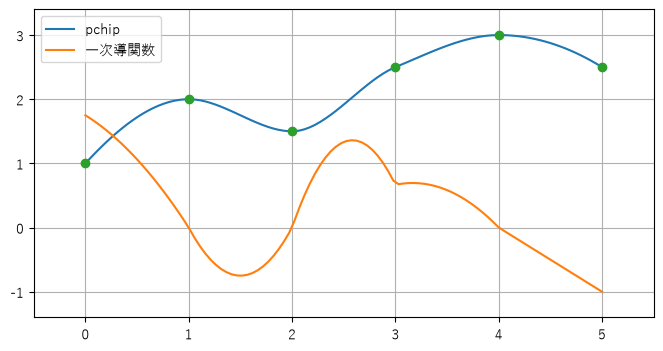

In [7]:
x = [0, 1, 2, 3, 4, 5]
y = [1, 2, 1.5, 2.5, 3, 2.5]
xs = np.linspace(x[0], x[-1], 100)
curve = interpolate.pchip(x, y)  # 単調な 3 次補間
ys = curve(xs)
dys = curve.derivative()(xs)     # 1 次導関数
plt.figure(figsize=(8, 4))
plt.plot(xs, ys, label="pchip")
plt.plot(xs, dys, label="一次導関数")
plt.plot(x, y, "o")
plt.legend(loc="best")
plt.grid()
plt.margins(0.1, 0.1)
plt.show()

## 多次元の補間

`RegularGridInterpolator` は、規則的なグリッド(等間隔でなくてもよい)上のデータを補間します。1 次元から 3 次元以上まで使えます。主な引数は次のとおりです。

| 引数 | 説明 |
|------|------|
| `points` | 各次元のグリッド点。`(x, y, z, ...)` のように、次元ごとに配列を並べる。 |
| `values` | 各グリッド点での値。`points` に対応する形の多次元配列。 |
| `method` | `"linear"`(既定)、`"cubic"`、`"nearest"` のいずれか。 |

次の例は、曲面のグリッド点を 2 次元で補間します。左が補間前、右が補間後です。

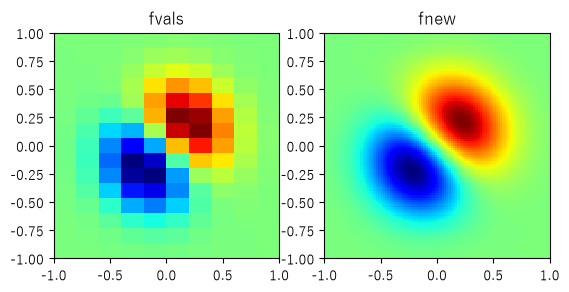

In [8]:
def func(x, y):  #❶ 曲面の高さ
    return (x + y) * np.exp(-5.0 * (x**2 + y**2))


y, x = np.ogrid[-1:1:15j, -1:1:10j]  #❷ 15×10 のグリッド
fvals = func(x, y)

interp_func = interpolate.RegularGridInterpolator(  #❸ 補間の準備
    (y.ravel(), x.ravel()), fvals, method="cubic"
)

Ynew, Xnew = np.ogrid[-1:1:100j, -1:1:100j]
fnew = interp_func((Xnew, Ynew))  # 100×100 で補間  #❹ 細かいグリッドで補間する

plt.subplot(121)
plt.imshow(
    fvals,
    extent=[-1, 1, -1, 1],
    cmap=plt.cm.jet,
    interpolation="nearest",
    origin="lower",
)
plt.title("fvals")
plt.subplot(122)
plt.imshow(
    fnew,
    extent=[-1, 1, -1, 1],
    cmap=plt.cm.jet,
    interpolation="nearest",
    origin="lower",
)
plt.title("fnew")
plt.show()

❶ `func` は、曲面の高さを返す関数です。❷ x と y を -1 から 1 まで、15×10 の等間隔グリッドで計算します。結果の `fvals` は、第 0 軸が y、第 1 軸が x に対応します。❸ グリッドの座標と値から、`RegularGridInterpolator` を作ります。ここでは 3 次の補間です。❹ オブジェクトは関数のように呼べるので、より細かいグリッドで高さを計算します。

### griddata

`RegularGridInterpolator` は、規則的なグリッドのデータだけを扱います。ばらばらに散らばった点のデータを補間するときは、`griddata()` を使います。呼び方は次のとおりです。

```python
griddata(points, values, xi, method='linear', fill_value=nan)
```

`points` は k 次元空間の座標で、形状 `(N, k)` の配列か、k 個の配列の並びです。`values` は各点の値、`xi` は補間する座標(形状 `(M, k)`)です。`method` は `'nearest'`、`'linear'`、`'cubic'` から選びます。

次のプログラムで試します。左が `'nearest'` で、各点は最も近いデータ点の値になります。そのため、同じ色のブロックが並びます。`'linear'` と `'cubic'` は、データ点の凸包の内側だけを補間し、外側は `fill_value` になります。中と右の白い部分が、凸包の外側です。

:::{warning}
`griddata()` はユークリッド距離で補間します。k 次元空間で各次元の値の範囲が大きく違うときは、データを正規化してから使ってください。
:::

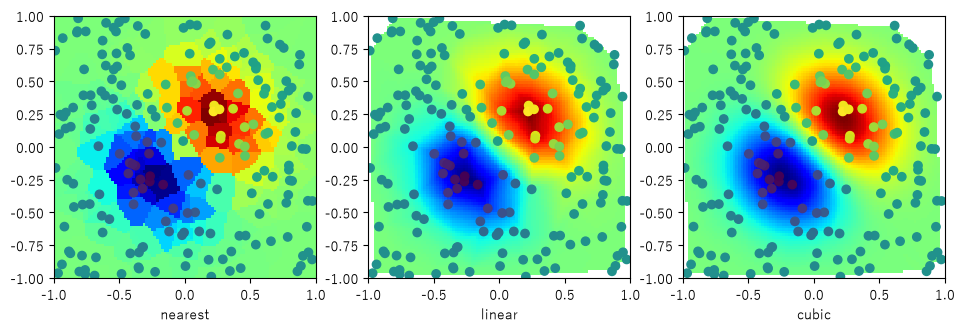

In [9]:
# ランダムな N 点の座標と、その点での関数値
N = 200
np.random.seed(42)
x = np.random.uniform(-1, 1, N)
y = np.random.uniform(-1, 1, N)
z = func(x, y)

yg, xg = np.mgrid[-1:1:100j, -1:1:100j]
xi = np.c_[xg.ravel(), yg.ravel()]

methods = "nearest", "linear", "cubic"

zgs = [
    interpolate.griddata((x, y), z, xi, method=method).reshape(100, 100)
    for method in methods
]

fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.5))

for ax, method, zg in zip(axes, methods, zgs):
    ax.imshow(
        zg,
        extent=[-1, 1, -1, 1],
        cmap=plt.cm.jet,
        interpolation="nearest",
        origin="lower",
    )
    ax.set_xlabel(method)
    ax.scatter(x, y, c=z)

plt.show()

### 放射基底関数補間

放射基底関数(RBF)補間も、ばらばらな点の補間に使えます。高次元のデータにも対応できます。放射基底関数は、ある点との距離だけで値が決まる関数 $\phi(\left\| \mathbf{x} - \mathbf{x}_i \right\|)$ です。$\mathbf{x}_i$ は与えられたデータ点です。これらの関数を足し合わせて、N 次元空間の関数を近似します。

$$y(\mathbf{x}) = \sum_{i=1}^N w_i \, \phi(\|\mathbf{x} - \mathbf{x}_i\|)$$

まず 1 次元で見てみます。次の図は、`multiquadric`、`gaussian`、`linear` の 3 つの関数で補間した結果です。

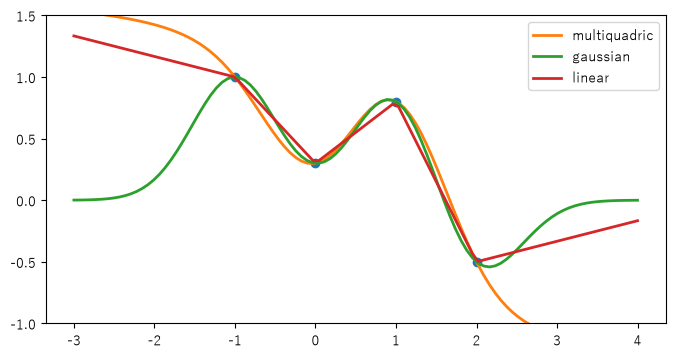

In [10]:
from scipy.interpolate import Rbf

x1 = np.array([-1, 0, 2.0, 1.0])
y1 = np.array([1.0, 0.3, -0.5, 0.8])

funcs = ["multiquadric", "gaussian", "linear"]
nx = np.linspace(-3, 4, 100)
rbfs = [Rbf(x1, y1, function=fname) for fname in funcs]  #❶ 各基底関数で補間する
rbf_ys = [rbf(nx) for rbf in rbfs]  #❷ 補間した値を計算する

plt.figure(figsize=(8, 4))
plt.plot(x1, y1, "o")
for fname, ny in zip(funcs, rbf_ys):
    plt.plot(nx, ny, label=fname, lw=2)

plt.ylim(-1.0, 1.5)
plt.legend()
plt.show()

❶ データ点 `x1`、`y1` から `Rbf` オブジェクトを作り、`function` で使う基底関数を選びます。❷ オブジェクトは関数のように呼べるので、`nx` の位置の値を計算します。

`Rbf` の `nodes` 属性に、係数 $w_i$ が入っています。

In [11]:
for fname, rbf in zip(funcs, rbfs):
    print(fname, rbf.nodes)

multiquadric [-0.88822885  2.17654513  1.42877511 -2.67919021]
gaussian [ 1.00321945 -0.02345964 -0.65441716  0.91375159]
linear [-0.26666667  0.6         0.73333333 -0.9       ]


2 次元の例です。

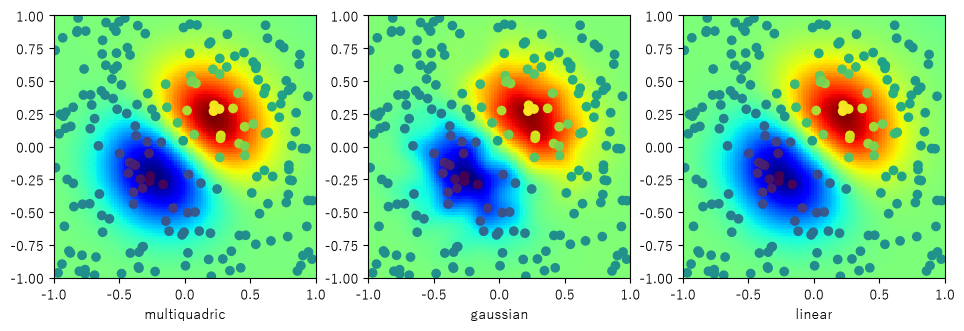

In [12]:
rbfs = [Rbf(x, y, z, function=fname) for fname in funcs]
rbf_zg = [rbf(xg, yg).reshape(xg.shape) for rbf in rbfs]

fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.5))
for ax, fname, zg in zip(axes, funcs, rbf_zg):
    ax.imshow(
        zg,
        extent=[-1, 1, -1, 1],
        cmap=plt.cm.jet,
        interpolation="nearest",
        origin="lower",
    )
    ax.set_xlabel(fname)
    ax.scatter(x, y, c=z)

plt.show()

基底関数によっては、`epsilon` で影響の範囲を指定できます。値が大きいほど、各点の影響が広がり、曲面はなめらかになります。次のコードは、`gaussian` の `epsilon` を変えた結果です。

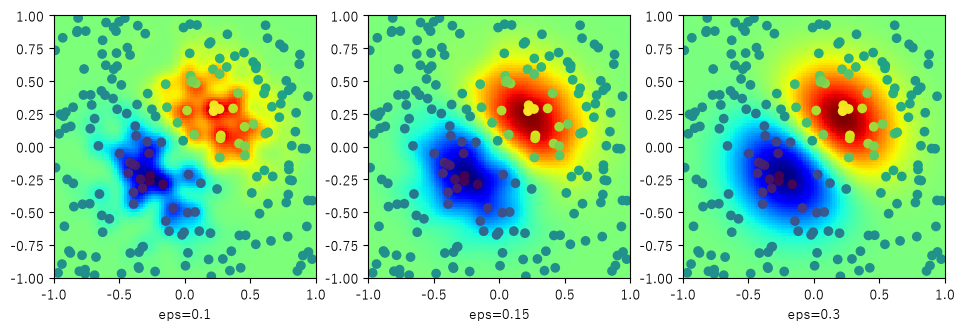

In [13]:
epsilons = 0.1, 0.15, 0.3
rbfs = [Rbf(x, y, z, function="gaussian", epsilon=eps) for eps in epsilons]
zgs = [rbf(xg, yg).reshape(xg.shape) for rbf in rbfs]

fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.5))
for ax, eps, zg in zip(axes, epsilons, zgs):
    ax.imshow(
        zg,
        extent=[-1, 1, -1, 1],
        cmap=plt.cm.jet,
        interpolation="nearest",
        origin="lower",
    )
    ax.set_xlabel("eps=%g" % eps)
    ax.scatter(x, y, c=z)

plt.show()

## まとめ

* 1 次元の補間は `interp1d()`。`kind` で次数と方法を選ぶ。範囲の外は計算できない。
* 外挿と平滑化が必要なら `UnivariateSpline()`。`s=0` ですべての点を通り、`s>0` で平滑化される。
* パラメトリック曲線は `splprep()` と `splev()` で補間する。
* 単調性を保ちたいときは `pchip()` を使う。
* 規則的なグリッドは `RegularGridInterpolator`、ばらばらな点は `griddata()` か `Rbf` で補間する。